In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ART = Path("artifacts"); (ART / "models").mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
from sklearn.inspection import permutation_importance

In [2]:
meta = json.load(open(ART / "meta.json"))
METALS, CATS, TARGETS = meta["METALS"], meta["CATS"], meta["TARGETS"]
FEATURES = METALS + CATS
train = pd.read_csv(ART / "train.csv")
test  = pd.read_csv(ART / "test.csv")
best_per_target = pd.read_csv(ART / "best_model_per_target.csv").set_index("target")
MODEL_NAMES = ["Ridge", "RandomForest", "GradientBoosting", "SVR"]
print("test rows:", len(test)); best_per_target[["model", "tuned_CV_RMSE"]]

test rows: 8


,model,tuned_CV_RMSE
target,,
DC,Ridge,0.000269
HEI,Ridge,0.000269
HPI,Ridge,0.000006


## 1. Metrics on the test set — all models
`Naive_mean` always predicts the training-set mean; a useful model must beat it.

In [3]:
def metrics(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

rows, preds = [], {}
for target in TARGETS:
    y_test = test[target]
    rows.append({"target": target, "model": "Naive_mean", "version": "-",
                 **metrics(y_test, np.full(len(test), train[target].mean()))})
    for name in MODEL_NAMES:
        for version in ["baseline", "tuned"]:
            m = joblib.load(ART / "models" / f"{version}_{target}_{name}.joblib")
            p = m.predict(test[FEATURES]); preds[(target, name, version)] = p
            rows.append({"target": target, "model": name, "version": version, **metrics(y_test, p)})

results = pd.DataFrame(rows)
results.to_csv(ART / "test_metrics_all_models.csv", index=False)
results.round(5)

,target,model,version,RMSE,MAE,R2
0,HPI,Naive_mean,-,0.00355,0.00336,-0.06977
1,HPI,Ridge,baseline,0.00052,0.00035,0.97692
2,HPI,Ridge,tuned,0.00000,0.00000,1.00000
3,HPI,RandomForest,baseline,0.00143,0.00116,0.82663
4,HPI,RandomForest,tuned,0.00185,0.00148,0.71037
5,HPI,GradientBoosting,baseline,0.00098,0.00061,0.91806
6,HPI,GradientBoosting,tuned,0.00094,0.00057,0.92597
7,HPI,SVR,baseline,0.00290,0.00196,0.28568
8,HPI,SVR,tuned,0.00369,0.00205,-0.15420
9,HEI,Naive_mean,-,0.07874,0.07086,-0.94743


## 2. The selected model per target (chosen in Notebook 2 by CV, tuned version)

In [4]:
sel = []
for target in TARGETS:
    name = best_per_target.loc[target, "model"]
    row = results.query("target == @target and model == @name and version == 'tuned'").iloc[0]
    naive = results.query("target == @target and model == 'Naive_mean'").iloc[0]
    sel.append({"target": target, "selected_model": name, "RMSE": row.RMSE, "MAE": row.MAE, "R2": row.R2,
                "naive_RMSE": naive.RMSE, "RMSE_vs_naive_%": 100 * (1 - row.RMSE / naive.RMSE)})
selected = pd.DataFrame(sel); selected.to_csv(ART / "test_metrics_selected.csv", index=False)
selected.round(5)

,target,selected_model,RMSE,MAE,R2,naive_RMSE,RMSE_vs_naive_%
0,HPI,Ridge,0.00000,0.00000,1.0,0.00355,99.97186
1,HEI,Ridge,0.00002,0.00001,1.0,0.07874,99.97099
2,DC,Ridge,0.00002,0.00001,1.0,0.07853,99.97075


## 3. Actual vs predicted

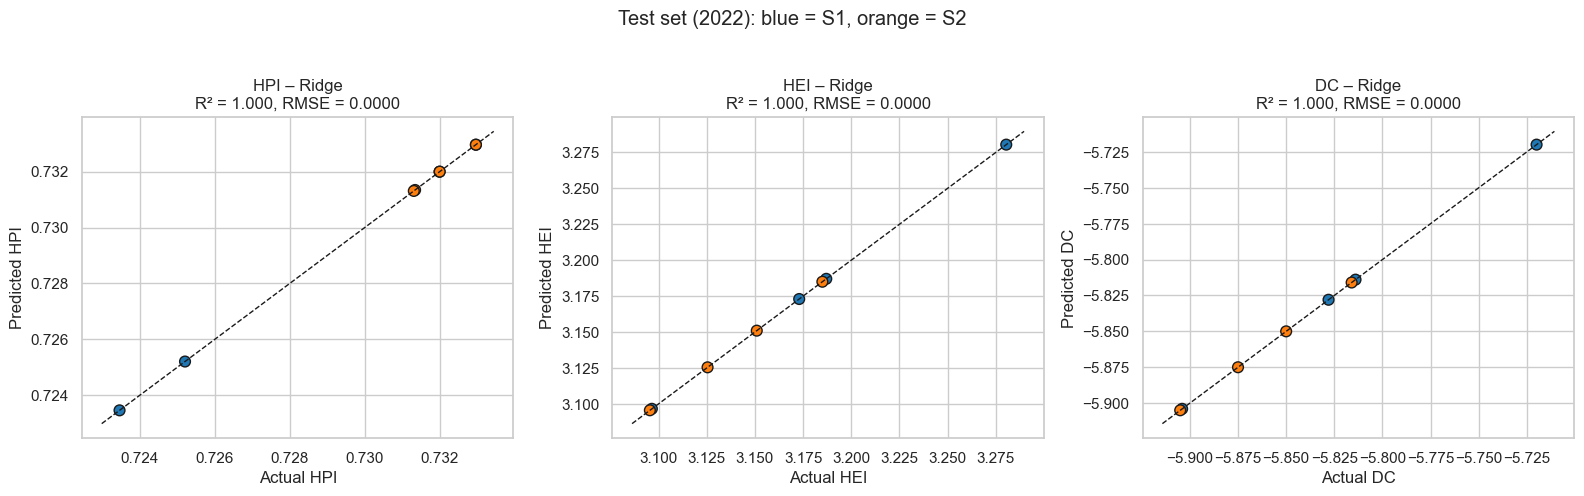

In [5]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(16, 4.8))
for ax, target in zip(axes, TARGETS):
    name = best_per_target.loc[target, "model"]
    y, p = test[target], preds[(target, name, "tuned")]
    ax.scatter(y, p, c=test["Site"].map({"S1": "tab:blue", "S2": "tab:orange"}), s=60, edgecolor="k")
    lo, hi = min(y.min(), p.min()), max(y.max(), p.max()); pad = 0.05 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], "k--", lw=1)
    ax.set_xlabel(f"Actual {target}"); ax.set_ylabel(f"Predicted {target}")
    ax.set_title(f"{target} – {name}\nR² = {r2_score(y, p):.3f}, RMSE = {np.sqrt(mean_squared_error(y, p)):.4f}")
plt.suptitle("Test set (2022): blue = S1, orange = S2", y=1.03); plt.tight_layout(); plt.show()

## 4. Residuals
Points close to zero = good predictions. Systematic patterns (e.g. one season always off) would hint at missing information.

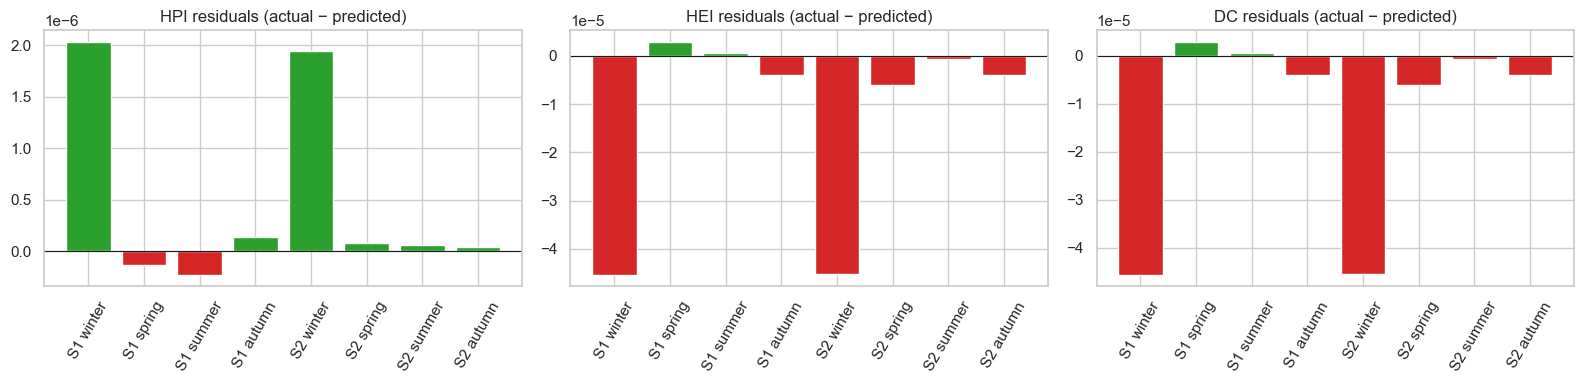

In [6]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(16, 4))
label = test["Site"] + " " + test["Month"]
for ax, target in zip(axes, TARGETS):
    name = best_per_target.loc[target, "model"]
    resid = test[target] - preds[(target, name, "tuned")]
    ax.bar(label, resid, color=np.where(resid >= 0, "tab:green", "tab:red")); ax.axhline(0, color="k", lw=.8)
    ax.set_title(f"{target} residuals (actual − predicted)"); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 5. Which inputs drive the predictions?
Permutation importance on the test set: how much the error grows when one input column is shuffled.

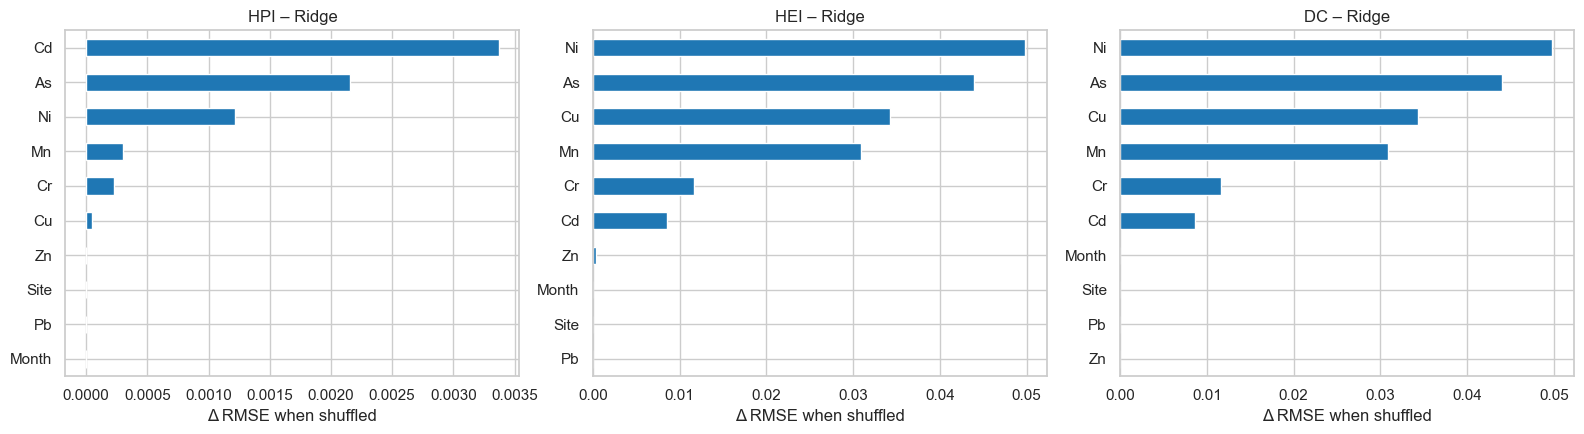

In [7]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(16, 4.5))
for ax, target in zip(axes, TARGETS):
    name = best_per_target.loc[target, "model"]
    m = joblib.load(ART / "models" / f"tuned_{target}_{name}.joblib")
    pi = permutation_importance(m, test[FEATURES], test[target], n_repeats=50, random_state=RANDOM_STATE,
                                scoring="neg_root_mean_squared_error")
    imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
    imp.plot.barh(ax=ax, color="tab:blue"); ax.set_title(f"{target} – {name}"); ax.set_xlabel("Δ RMSE when shuffled")
plt.tight_layout(); plt.show()

## 6. Save the predictions

In [8]:
out = test[["Site", "Year", "Month"]].copy()
for target in TARGETS:
    name = best_per_target.loc[target, "model"]
    out[f"{target}_actual"] = test[target]
    out[f"{target}_predicted"] = preds[(target, name, "tuned")]
    out[f"{target}_error"] = out[f"{target}_actual"] - out[f"{target}_predicted"]
out.to_csv("predictions_test_2022.csv", index=False)
out.round(5)

,Site,Year,Month,HPI_actual,HPI_predicted,HPI_error,HEI_actual,HEI_predicted,HEI_error,DC_actual,DC_predicted,DC_error
0,S1,2022,winter,0.73296,0.73296,0.0,3.09651,3.09656,-0.00005,-5.904,-5.90395,-0.00005
1,S1,2022,spring,0.72521,0.72521,-0.0,3.28041,3.28040,0.00000,-5.720,-5.72000,0.00000
2,S1,2022,summer,0.72347,0.72347,-0.0,3.17297,3.17297,0.00000,-5.828,-5.82800,0.00000
3,S1,2022,autumn,0.73200,0.73199,0.0,3.18701,3.18702,-0.00000,-5.814,-5.81400,-0.00000
4,S2,2022,winter,0.73296,0.73296,0.0,3.09549,3.09553,-0.00005,-5.905,-5.90495,-0.00005
5,S2,2022,spring,0.73134,0.73134,0.0,3.12542,3.12543,-0.00001,-5.875,-5.87499,-0.00001
6,S2,2022,summer,0.73131,0.73131,0.0,3.15095,3.15095,-0.00000,-5.850,-5.85000,-0.00000
7,S2,2022,autumn,0.73200,0.73200,0.0,3.18499,3.18500,-0.00000,-5.816,-5.81600,-0.00000
